# [Bonus Tasks](svm_segm.ipynb)

In [20]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

<Figure size 640x480 with 0 Axes>

In [21]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [22]:
patch_sizes = (32, 32)

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [23]:
def create_data_matrix(img):
    blocks = skimage.util.view_as_blocks(img, patch_sizes)
    X = blocks.reshape(-1, patch_sizes[0] * patch_sizes[1])
    return X

**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [24]:
def create_gt_labels_vector(gt):
    anteil = create_data_matrix(gt > 0).mean(axis=1)
    y = np.where(anteil > 0.5, 1, np.where(anteil == 0, -1, 0))
    return y

**[Task 1.3.]()** Create the SVM classifier:

In [25]:
clf = make_pipeline(StandardScaler(), \
SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [26]:
im33 = plt.imread('data/NIH3T3/im/dna-33.png')
im44 = plt.imread('data/NIH3T3/im/dna-44.png')

X33 = create_data_matrix(im33)
X44 = create_data_matrix(im44)


**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [27]:
gt33 = plt.imread('data/NIH3T3/gt/33.png')
gt44 = plt.imread('data/NIH3T3/gt/44.png')

y33 = create_gt_labels_vector(gt33)
y44 = create_gt_labels_vector(gt44)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [28]:
X_all = np.concatenate([X33, X44], axis=0)
Y_all = np.concatenate([y33, y44], axis=0)

valid = (Y_all == -1) | (Y_all == 1)
X = X_all[valid]
Y = Y_all[valid]

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [29]:
clf.fit(X, Y)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(class_weight='balanced', gamma=0.1))])

**[Task 1.4.]()** Implement the function `predict_image`:

In [42]:
from skimage.transform import resize

def predict_image(img):
    X = create_data_matrix(img)
    preds = (clf.predict(X) == 1)

    n_rows = img.shape[0] // patch_sizes[0]
    n_cols = img.shape[1] // patch_sizes[1]
    img_pred = preds.reshape(n_rows, n_cols)
    img_2 = resize(img_pred, img.shape, order=0)
    
    return img_2

Test your implementation:

<function matplotlib.pyplot.show(close=None, block=None)>

<Figure size 640x480 with 0 Axes>

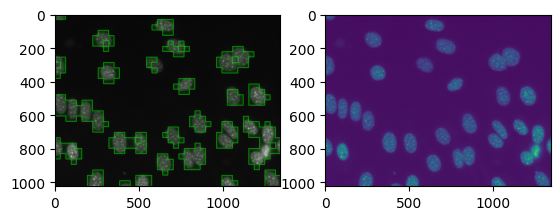

In [43]:
plt.figure()
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img)

plt.figure()
plt.subplot(1,2,1)
plt.imshow(blend_result(img, seg))
plt.subplot(1,2,2)
plt.imshow(img)
plt.show

**[Task 1.5.]()** Perform batch processing:

Image 28: 0.7209812219847866
Image 29: 0.6600878826245624
Image 33: 0.6778978154021594
Image 44: 0.7125355936692934
Image 46: 0.6171491101827866
Image 49: 0.6889506296603939
Mean: 0.6796003755873304


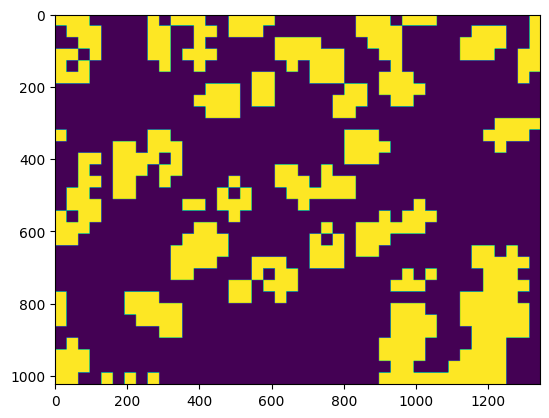

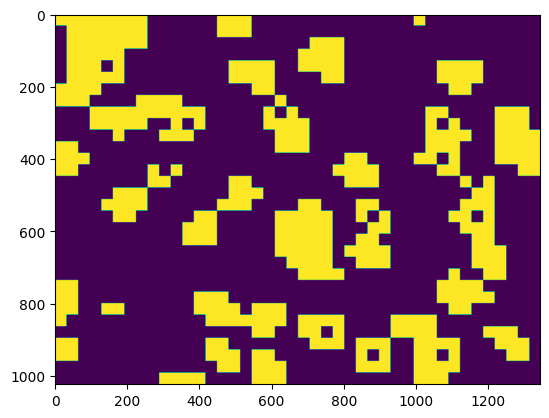

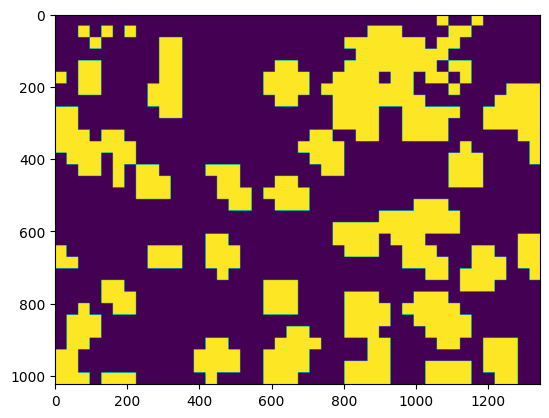

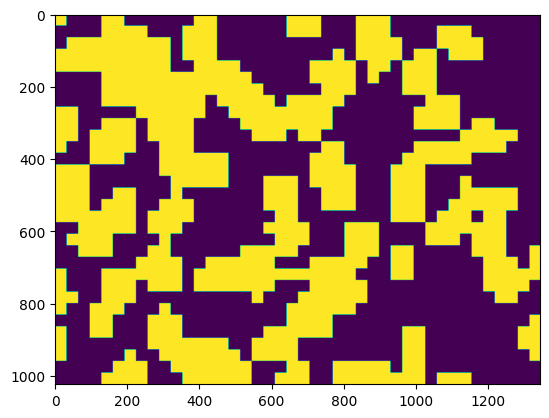

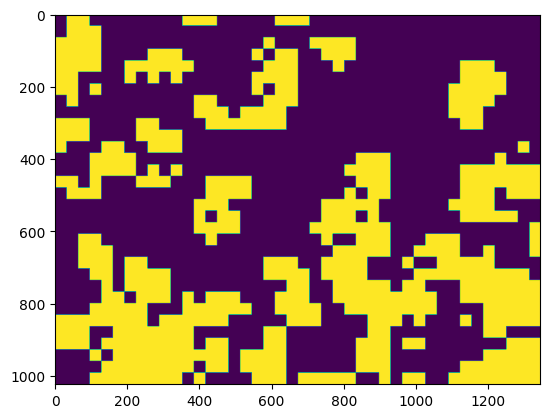

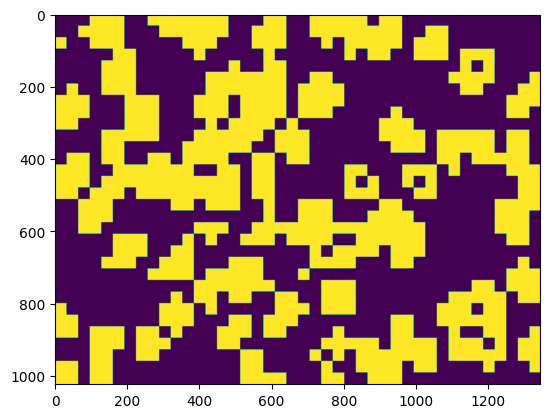

In [55]:
dice_scores = []
img_is = [28,29,33,44,46,49]

for i in img_is:
    img = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    gt = plt.imread(f'data/NIH3T3/gt/{i}.png') 
    
    seg = predict_image(img)

    dice = 2.0 * np.sum(seg*gt) / (np.sum(seg) + np.sum(gt))
    dice_scores.append(dice)
    print(f'Image {i}: {dice}')
    plt.figure()
    plt.imshow(seg)
    plt.show

print('Mean: ' + str(np.mean(dice_scores)))

